In [2]:
#https://morris-lab.github.io/CellOracle.documentation/notebooks/05_simulation/Gata1_KO_simulation_with_Paul_etal_2015_data.html#2.-Make-predictive-models-for-simulation
## Before running CellOracle, first run Monocle3 pseudotime to determine the pseudotime
import celloracle as co
import os
import sys

import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
%config InlineBackend.figure_format = 'retina'
%matplotlib inline

plt.rcParams['figure.figsize'] = [6, 4.5]
plt.rcParams["savefig.dpi"] = 500

save_folder = "./celloracle"
os.makedirs(save_folder, exist_ok=True)

In [3]:
co.__version__  

'0.20.0'

In [12]:
#If your scRNA-seq data includes more than 20-30K cells, we recommend downsampling your data. 
    #If you do not, please note the perturbation simulations may require large amounts of memory in the next notebook.
#adata1 = co.data.load_Paul2015_data()
adata = sc.read("./scRNA/scvelo1.h5ad")
adata.obs['Celltype']=adata.obs['sub.cluster']
sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.log1p(adata)
adata

AnnData object with n_obs × n_vars = 4260 × 22177
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Type', 'ident', 'scDblFinder.class', 'RNA_snn_res.0.4', 'seurat_clusters', 'Celltype', 'oldType', 'Celltype_all', 'RNA_snn_res.0.2', 'sub.cluster', 'pseudotime', 'nCount_spliced', 'nFeature_spliced', 'nCount_unspliced', 'nFeature_unspliced', 'barcode'
    uns: 'log1p'
    obsm: 'X_pca', 'X_umap'

In [13]:
# Random downsampling into 30K cells if the anndata object include more than 30 K cells.
n_cells_downsample = 30000
if adata.shape[0] > n_cells_downsample:
    # Let's dowmsample into 30K cells
    sc.pp.subsample(adata, n_obs=n_cells_downsample, random_state=123)
print(f"Cell number is :{adata.shape[0]}")

Cell number is :4260


In [14]:
# Load TF info which was made from mouse cell atlas dataset.
# Select the species
#base_GRN = co.data.load_human_promoter_base_GRN()#for Human: 
base_GRN = co.data.load_mouse_scATAC_atlas_base_GRN()#for mouse
# Check data
base_GRN.head()

,peak_id,gene_short_name,9430076c15rik,Ac002126.6,Ac012531.1,Ac226150.2,Afp,Ahr,Ahrr,Aire,...,Znf784,Znf8,Znf816,Znf85,Zscan10,Zscan16,Zscan22,Zscan26,Zscan31,Zscan4
0,chr10_100050979_100052296,4930430F08Rik,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,chr10_101006922_101007748,SNORA17,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,chr10_101144061_101145000,Mgat4c,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,chr10_10148873_10149183,9130014G24Rik,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,chr10_10149425_10149815,9130014G24Rik,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [15]:
# Instantiate Oracle object
oracle = co.Oracle()
print("Metadata columns :", list(adata.obs.columns))
print("Dimensional reduction: ", list(adata.obsm.keys()))

Metadata columns : ['orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Type', 'ident', 'scDblFinder.class', 'RNA_snn_res.0.4', 'seurat_clusters', 'Celltype', 'oldType', 'Celltype_all', 'RNA_snn_res.0.2', 'sub.cluster', 'pseudotime', 'nCount_spliced', 'nFeature_spliced', 'nCount_unspliced', 'nFeature_unspliced', 'barcode']
Dimensional reduction:  ['X_pca', 'X_umap']


In [16]:
print(adata.layers.keys())

KeysView(Layers with keys: )


22177 genes were found in the adata. Note that Celloracle is intended to use around 1000-3000 genes, so the behavior with this number of genes may differ from what is expected.


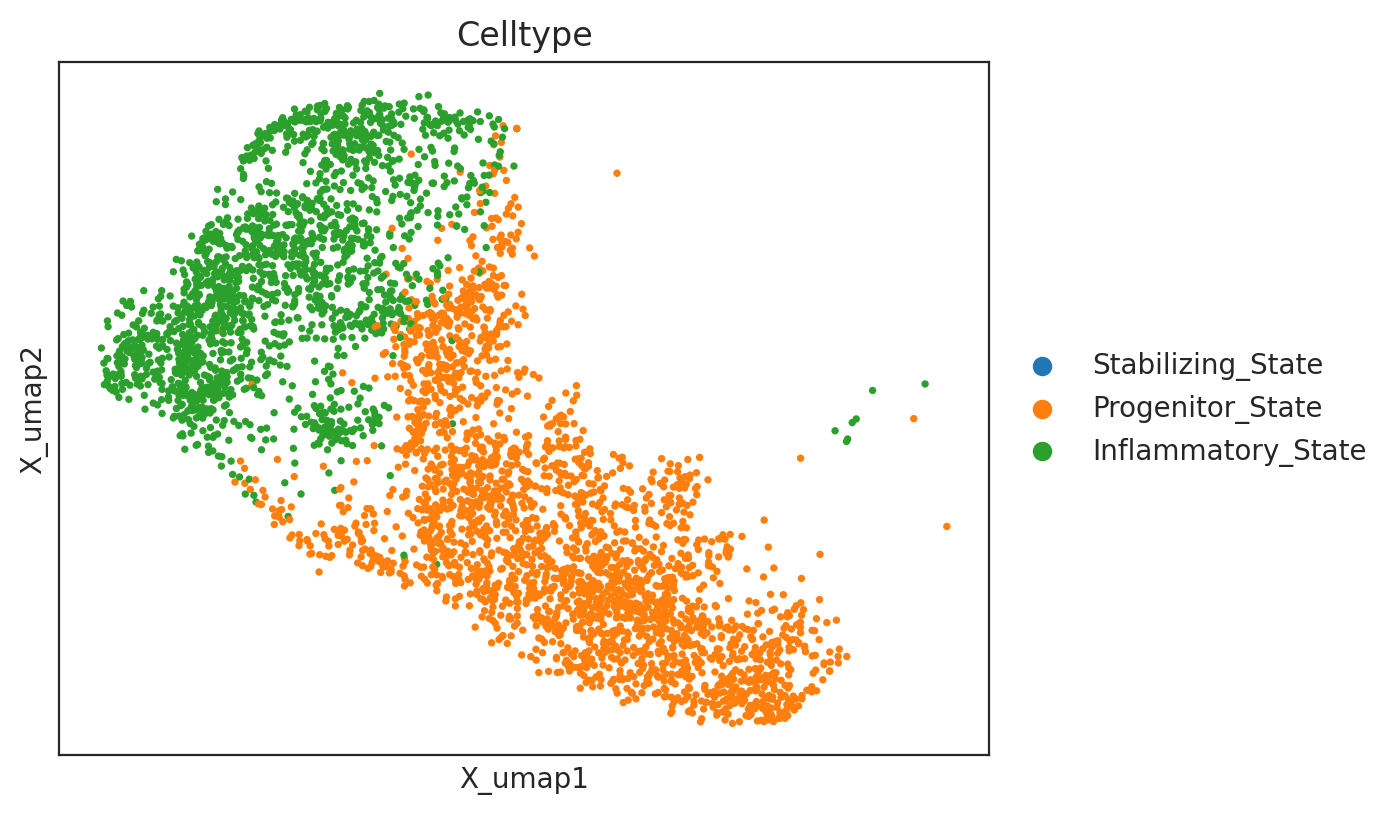

In [17]:
# In this notebook, we use the unscaled mRNA count for the nput of Oracle object.
adata.X = adata.X.copy()

# Instantiate Oracle object.
oracle.import_anndata_as_raw_count(adata=adata,
                                   cluster_column_name="Celltype",##cluster name
                                   embedding_name="X_umap")###UMAP embedding

In [18]:
# You can load TF info dataframe with the following code.
oracle.import_TF_data(TF_info_matrix=base_GRN)

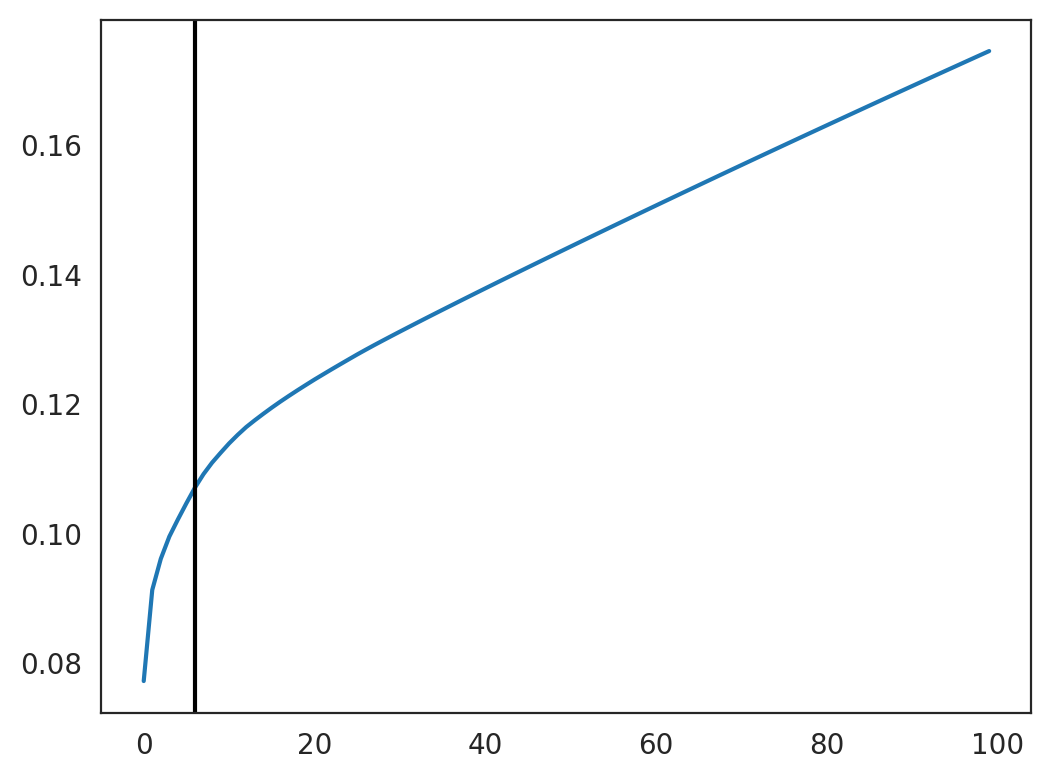

6
cell number is :4260
Auto-selected k is :106


In [19]:
#KNN imputation
# Perform PCA
oracle.perform_PCA()

# Select important PCs
plt.plot(np.cumsum(oracle.pca.explained_variance_ratio_)[:100])
n_comps = np.where(np.diff(np.diff(np.cumsum(oracle.pca.explained_variance_ratio_))>0.002))[0][0]
plt.axvline(n_comps, c="k")
plt.show()
print(n_comps)
n_comps = min(n_comps, 50)

n_cell = oracle.adata.shape[0]
print(f"cell number is :{n_cell}")

k = int(0.025*n_cell)
print(f"Auto-selected k is :{k}")

oracle.knn_imputation(n_pca_dims=n_comps, k=k, balanced=True, b_sight=k*8,
                      b_maxl=k*4, n_jobs=4)

In [20]:
oracle

Oracle object

Meta data
    celloracle version used for instantiation: 0.20.0
    n_cells: 4260
    n_genes: 22177
    cluster_name: Celltype
    dimensional_reduction_name: X_umap
    n_target_genes_in_TFdict: 21256 genes
    n_regulatory_in_TFdict: 1093 genes
    n_regulatory_in_both_TFdict_and_scRNA-seq: 664 genes
    n_target_genes_both_TFdict_and_scRNA-seq: 15328 genes
    k_for_knn_imputation: 106
Status
    Gene expression matrix: Ready
    BaseGRN: Ready
    PCA calculation: Done
    Knn imputation: Done
    GRN calculation for simulation: Not finished

In [21]:
%%time  
## Rate limit
# Calculate GRN for each population in "louvain_annot" clustering unit.
# This step may take some time.(~30 minutes)
links = oracle.get_links(cluster_name_for_GRN_unit="Celltype",######cluster name
                         alpha=10,
                         verbose_level=10)

  0%|          | 0/2 [00:00<?, ?it/s]

Inferring GRN for Inflammatory_State...


  0%|          | 0/15328 [00:00<?, ?it/s]

Inferring GRN for Progenitor_State...


  0%|          | 0/15328 [00:00<?, ?it/s]

CPU times: user 47min 16s, sys: 1min 17s, total: 48min 33s
Wall time: 1h 41min 3s


In [22]:
links.filter_links(p=0.001, weight="coef_abs", threshold_number=2000)

In [23]:
links.filter_links()
oracle.get_cluster_specific_TFdict_from_Links(links_object=links)
oracle.fit_GRN_for_simulation(alpha=10,
                              use_cluster_specific_TFdict=True)

  0%|          | 0/2 [00:00<?, ?it/s]

In [24]:
adata

AnnData object with n_obs × n_vars = 4260 × 22177
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Type', 'ident', 'scDblFinder.class', 'RNA_snn_res.0.4', 'seurat_clusters', 'Celltype', 'oldType', 'Celltype_all', 'RNA_snn_res.0.2', 'sub.cluster', 'pseudotime', 'nCount_spliced', 'nFeature_spliced', 'nCount_unspliced', 'nFeature_unspliced', 'barcode'
    uns: 'log1p'
    obsm: 'X_pca', 'X_umap'

In [ ]:
#color_palette = ["#00AFBB", "#E7B800", "#FC4E07"]
#oracle.update_cluster_colors(color_palette)

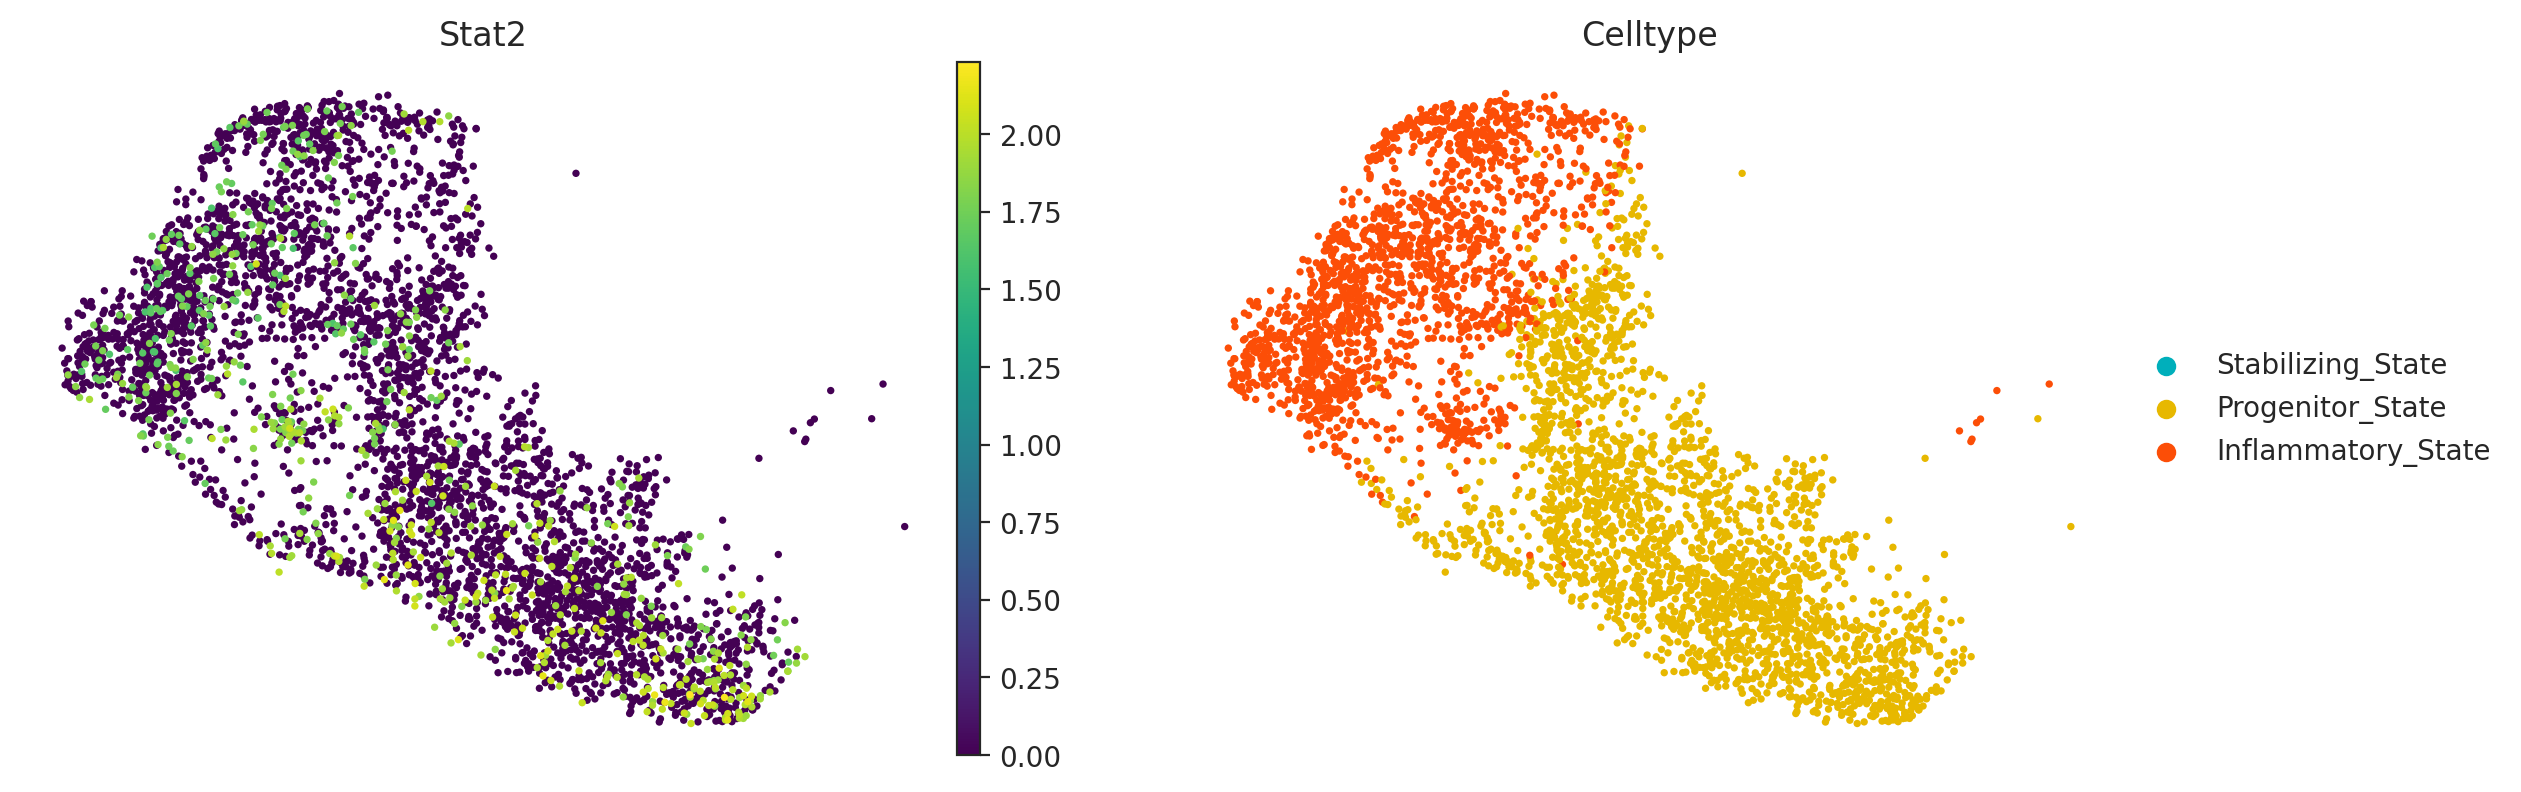

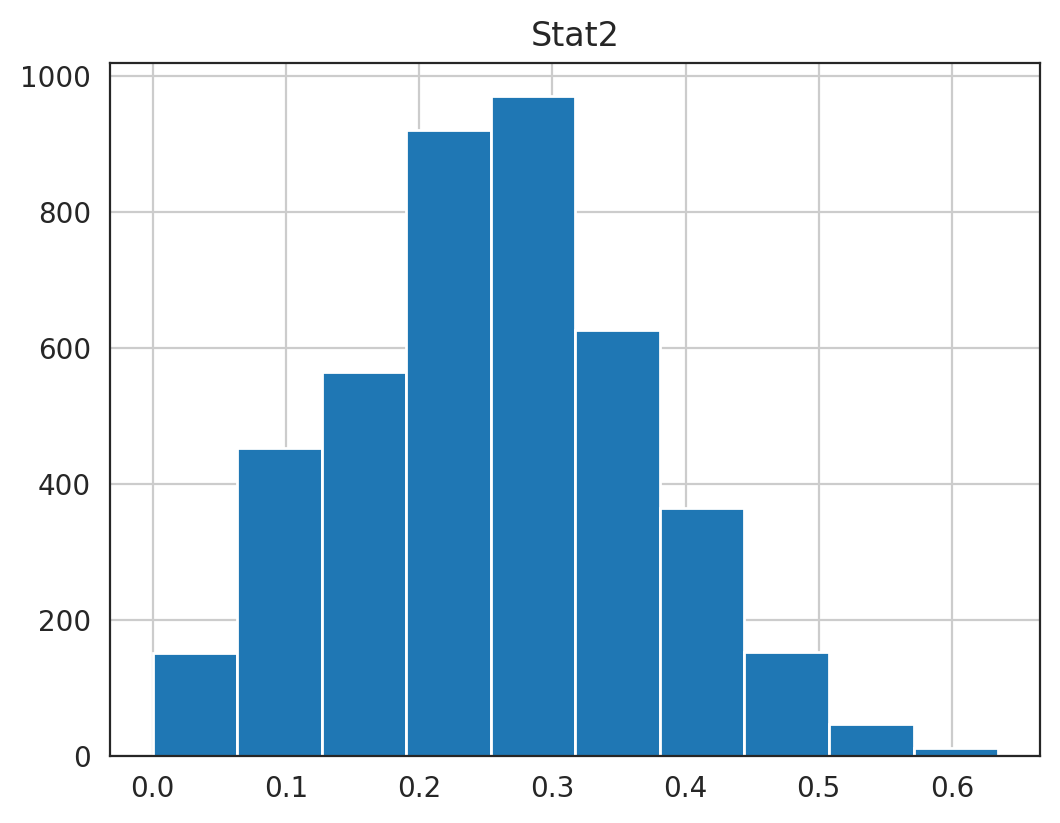

In [126]:
# Check gene expression
goi = "Stat2"
sc.pl.umap(oracle.adata, 
           color=["Stat2", oracle.cluster_column_name],
           use_raw=False, 
           cmap="viridis",
           ncols=2,  # display in two columns
           frameon=False,
           show=False)

sc.get.obs_df(oracle.adata, keys=[goi], 
              layer="imputed_count").hist()
plt.show()

In [127]:
# Enter perturbation conditions to simulate signal propagation after the perturbation.
##### KO genes
oracle.simulate_shift(perturb_condition={goi: 0.0},
                      n_propagation=3)

In [120]:
#You can use any gene expression value in the in silico perturbations, 
#but please avoid extremely high values that are far from the natural gene expression range. 
#The upper limit allowed is twice the maximum gene expression. 
# The maximum OE is twice the maximum value
##over expression
oracle.simulate_shift(perturb_condition={goi: 1.8},
                      n_propagation=3)

In [128]:
# Get transition probability
oracle.estimate_transition_prob(n_neighbors=200,
                                knn_random=True,
                                sampled_fraction=1)

# Calculate embedding
oracle.calculate_embedding_shift(sigma_corr=0.05)

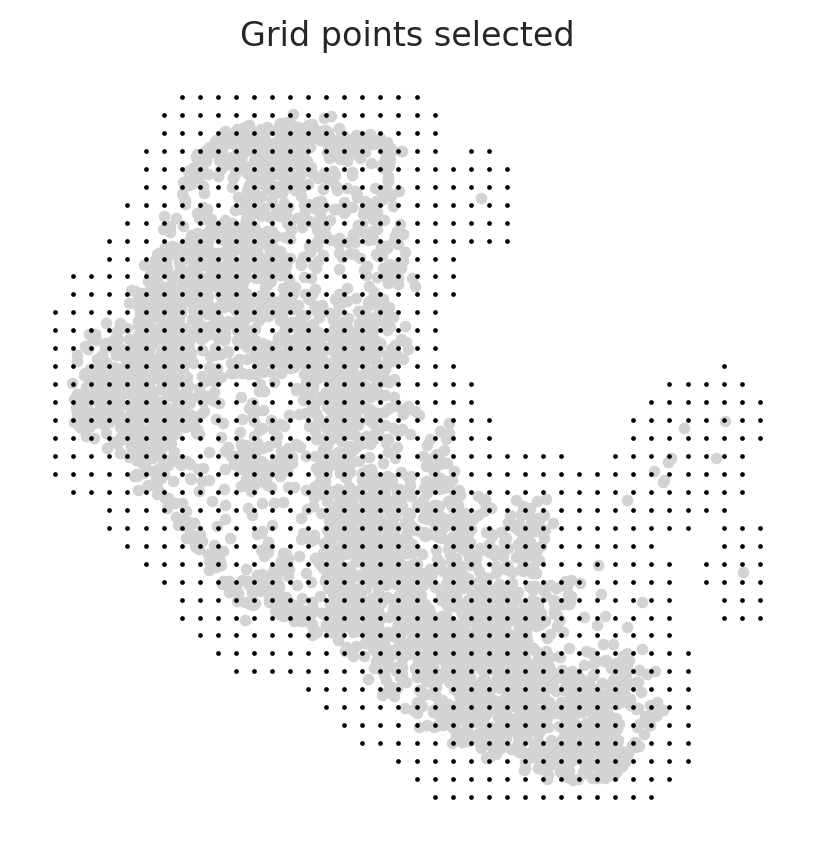

In [129]:
n_grid = 40
oracle.calculate_p_mass(smooth=0.8, n_grid=n_grid, n_neighbors=200)
min_mass = 0.01
oracle.calculate_mass_filter(min_mass=min_mass, plot=True)

Text(0.5, 1.0, 'Randomized simulation vector')

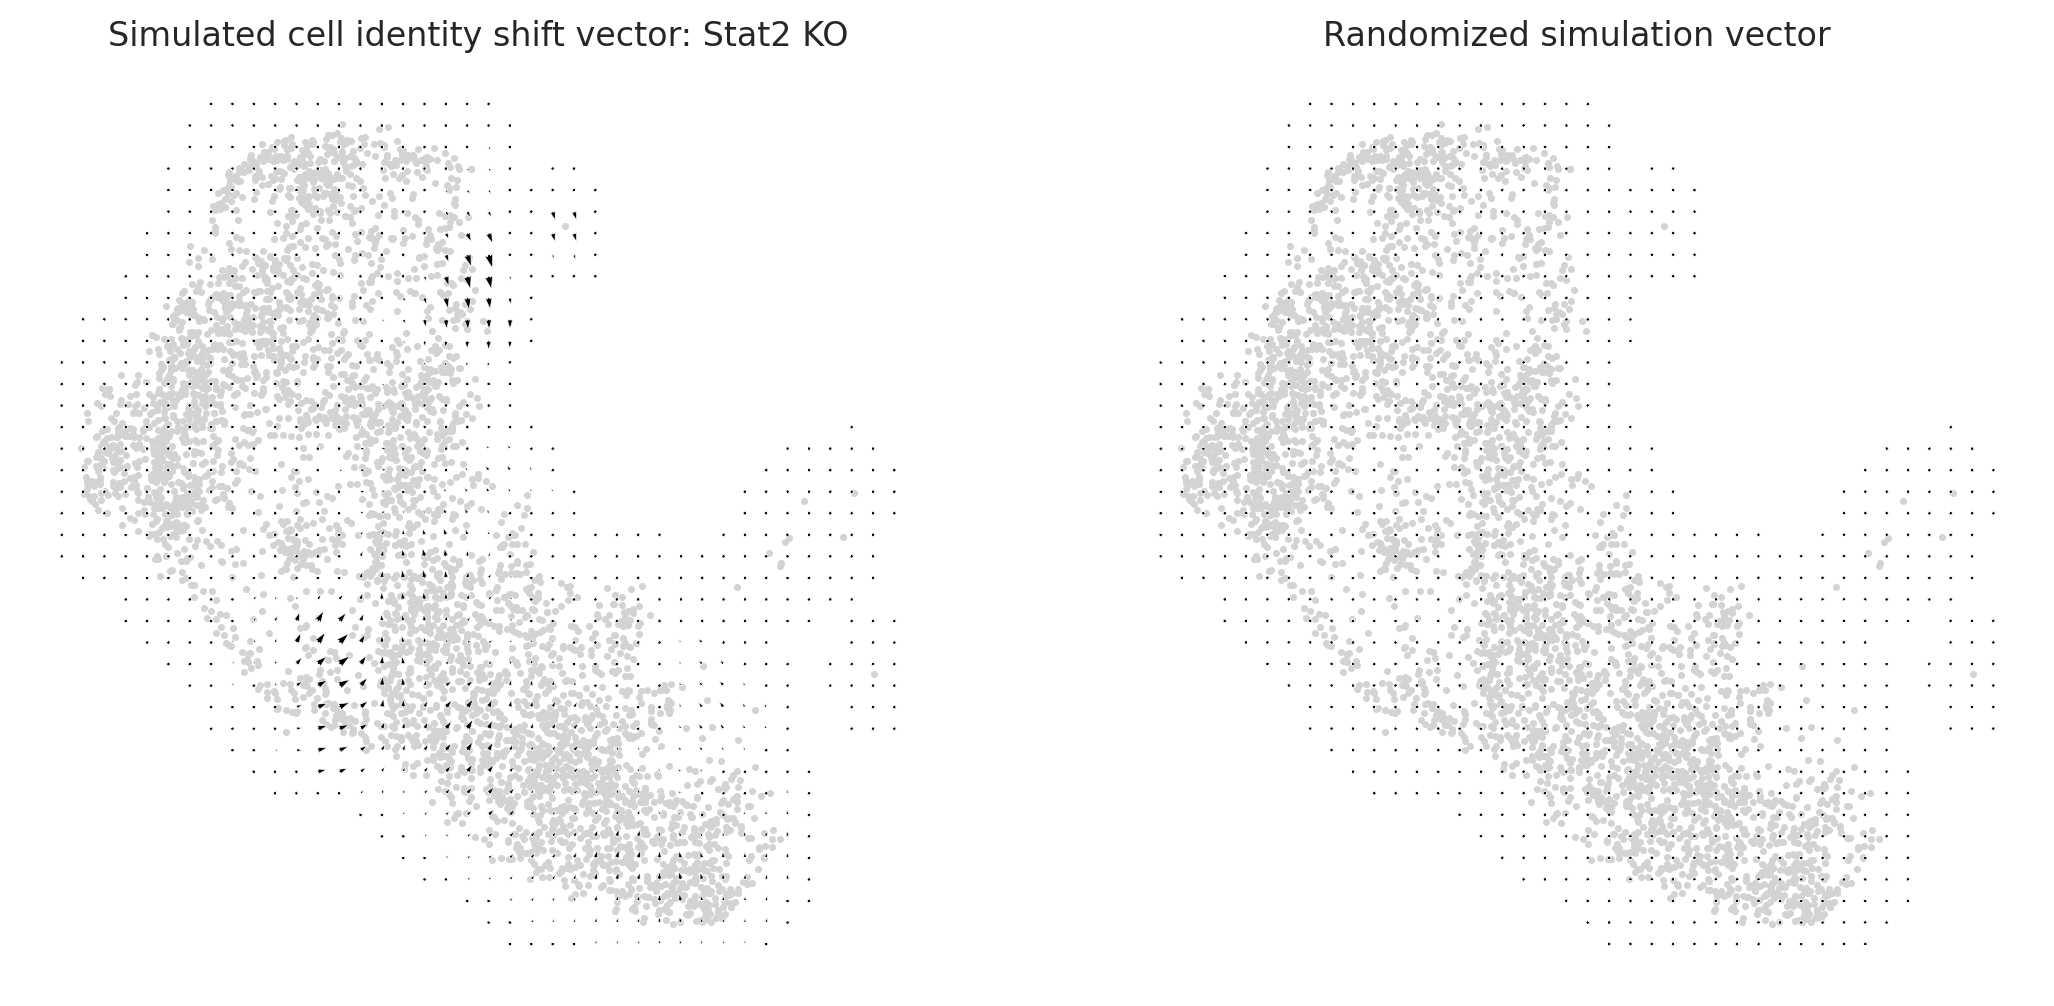

In [130]:
fig, ax = plt.subplots(1, 2,  figsize=[13, 6])
#########################
#########################
scale_simulation = 18# The larger the value, the smaller the arrows
#########################
#########################
# Show quiver plot
oracle.plot_simulation_flow_on_grid(scale=scale_simulation, ax=ax[0])
ax[0].set_title(f"Simulated cell identity shift vector: {goi} KO")

# Show quiver plot that was calculated with randomized graph.
oracle.plot_simulation_flow_random_on_grid(scale=scale_simulation, ax=ax[1])
ax[1].set_title(f"Randomized simulation vector")


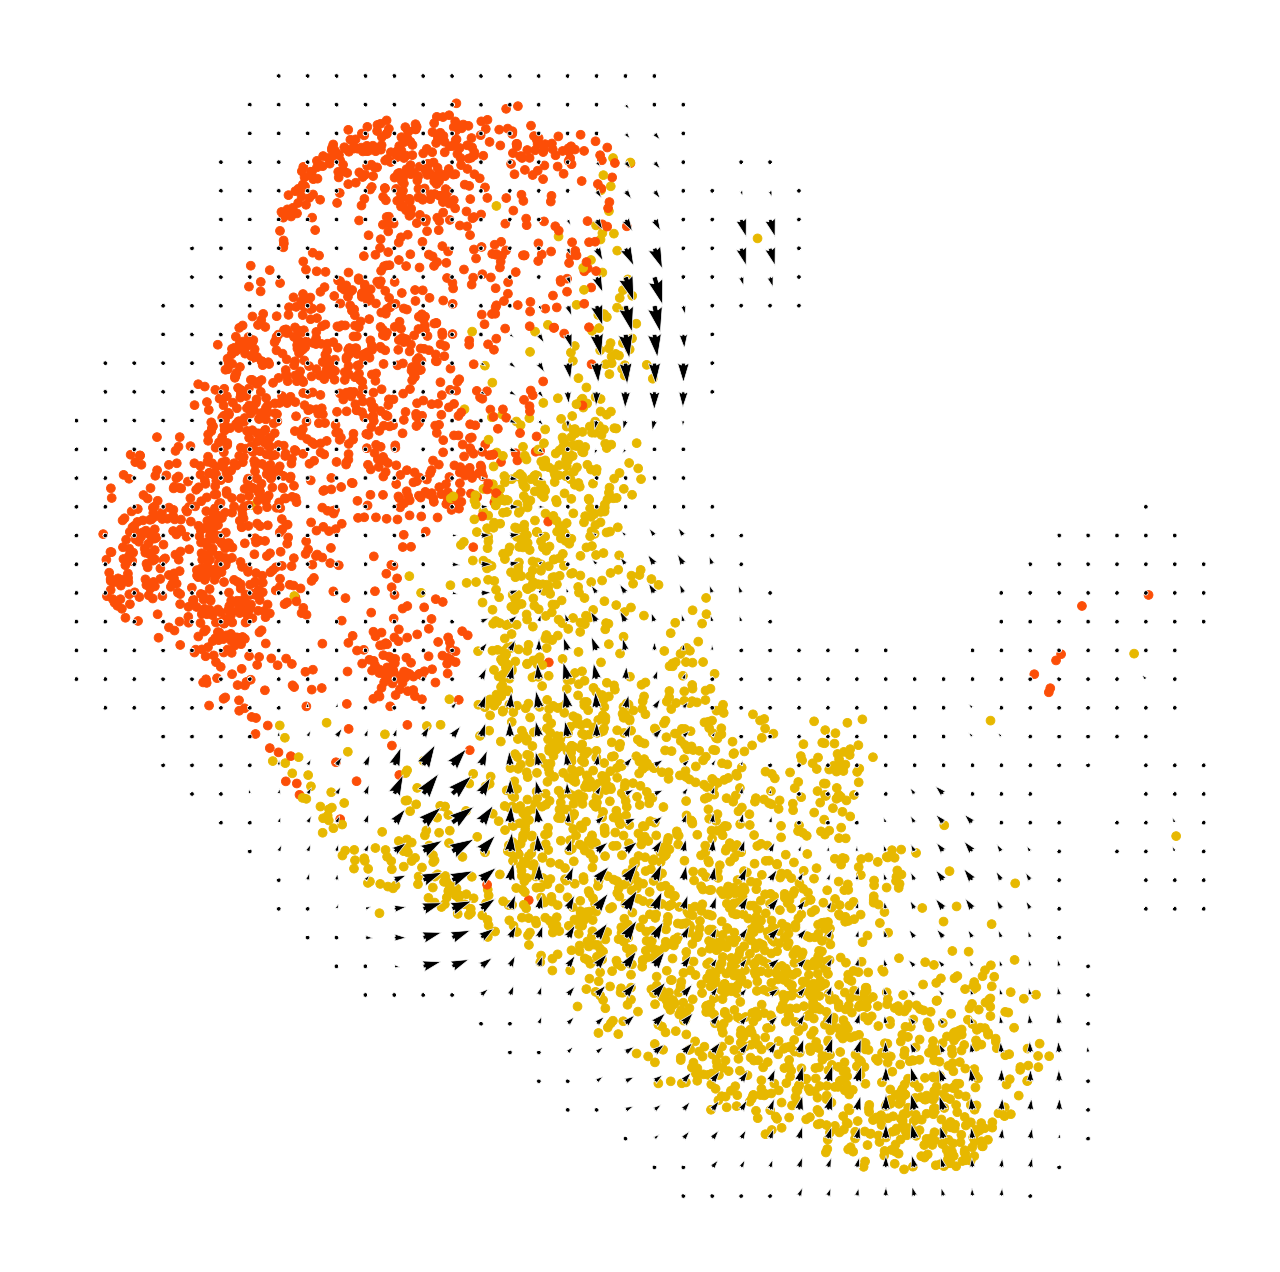

In [131]:
fig, ax = plt.subplots(figsize=[8, 8])

oracle.plot_cluster_whole(ax=ax, s=10)
oracle.plot_simulation_flow_on_grid(scale=12, ax=ax, show_background=False)

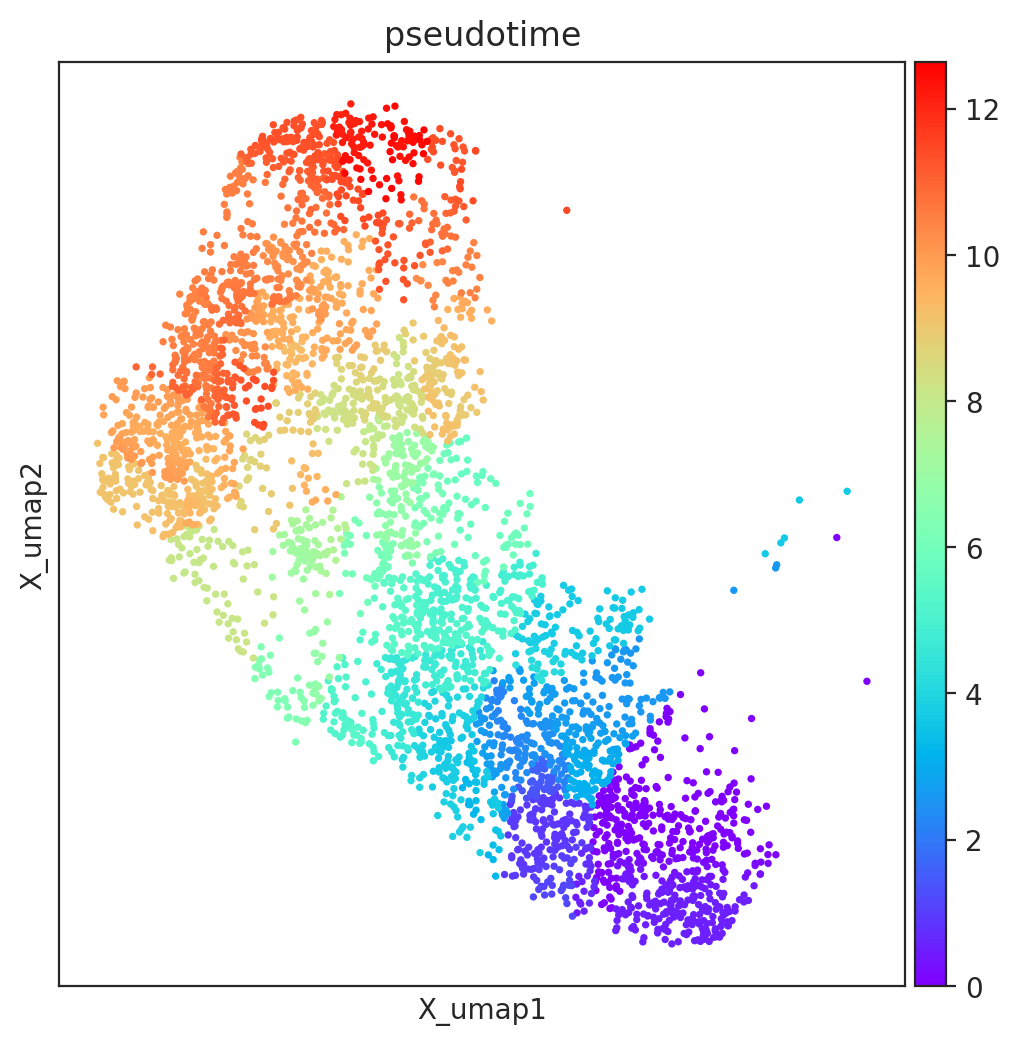

In [98]:
fig, ax = plt.subplots(figsize=[6,6])
sc.pl.embedding(adata=oracle.adata, basis=oracle.embedding_name, ax=ax, cmap="rainbow",
                color=["pseudotime"])### pseudotime

In [99]:
from celloracle.applications import Gradient_calculator

# Instantiate Gradient calculator object
gradient = Gradient_calculator(oracle_object=oracle, pseudotime_key="pseudotime")### pseudotime

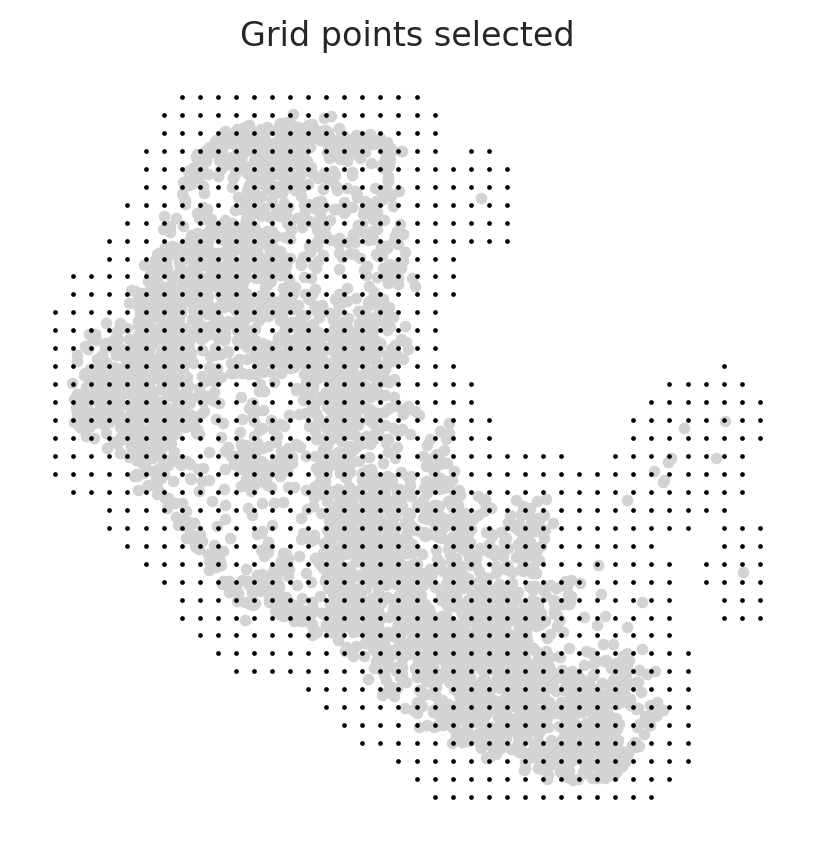

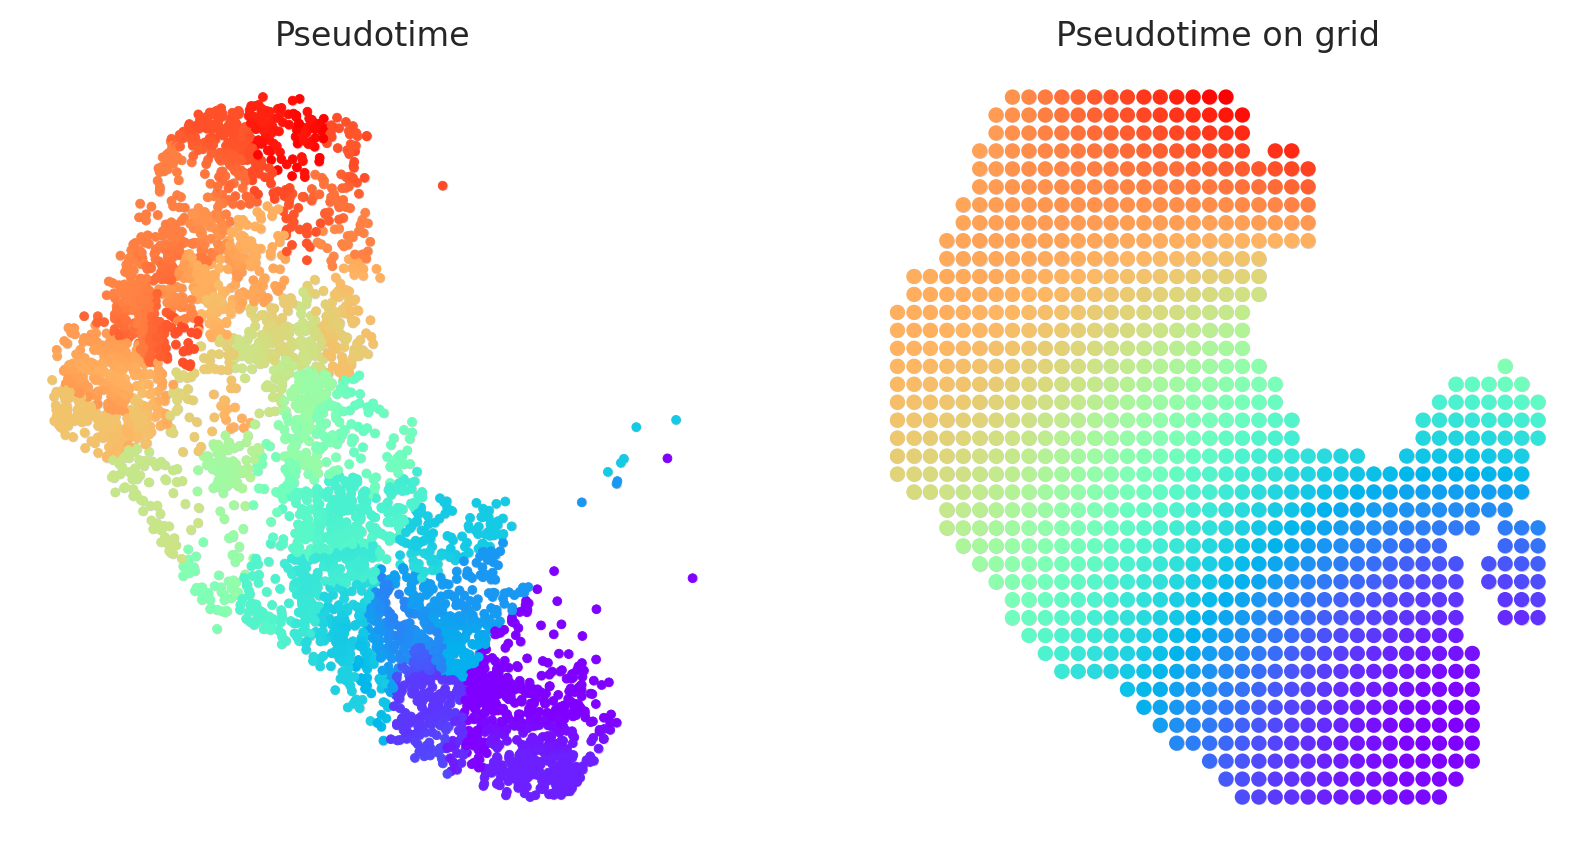

In [100]:
gradient.calculate_p_mass(smooth=0.8, n_grid=n_grid, n_neighbors=200)
gradient.calculate_mass_filter(min_mass=min_mass, plot=True)
gradient.transfer_data_into_grid(args={"method": "polynomial", "n_poly":3}, plot=True)
# Calculate graddient
gradient.calculate_gradient()

# Show results
scale_dev = 40
gradient.visualize_results(scale=scale_dev, s=5)
plt.close()

In [101]:
from celloracle.applications import Oracle_development_module

# Make Oracle_development_module to compare two vector field
dev = Oracle_development_module()

# Load development flow
dev.load_differentiation_reference_data(gradient_object=gradient)

# Load simulation result
dev.load_perturb_simulation_data(oracle_object=oracle)


# Calculate inner produc scores
dev.calculate_inner_product()
dev.calculate_digitized_ip(n_bins=10)

In [102]:
# Show perturbation scores
vm = 0.02

fig, ax = plt.subplots(1, 2, figsize=[12, 6])
dev.plot_inner_product_on_grid(vm=0.02, s=50, ax=ax[0])
ax[0].set_title(f"PS")

dev.plot_inner_product_random_on_grid(vm=vm, s=50, ax=ax[1])
ax[1].set_title(f"PS calculated with Randomized simulation vector")
plt.close()

In [103]:
from celloracle.visualizations.config import CONFIG
CONFIG["cmap_ps"] = "coolwarm"  # choose color   plasma  cividis  inferno magma coolwarm viridis

Figure saved to: ./celloracle/Celloracle.PNG


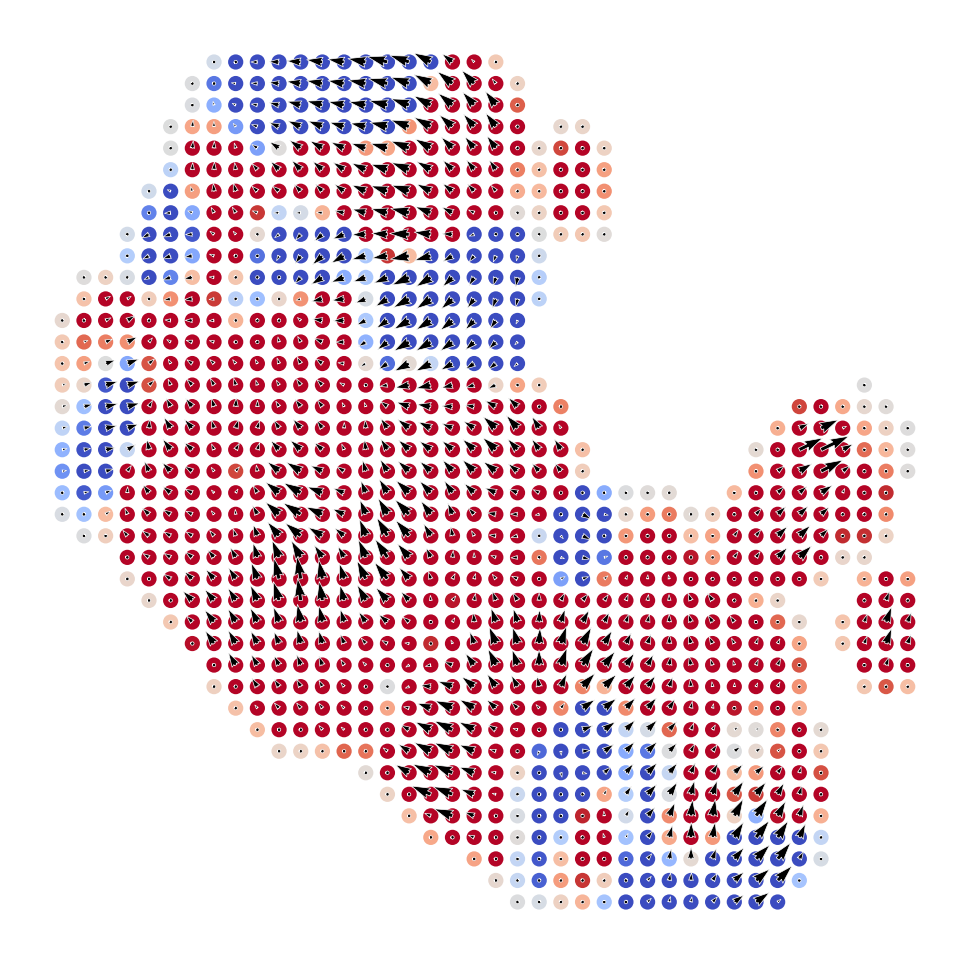

In [78]:
# Show perturbation scores with perturbation simulation vector field
fig, ax = plt.subplots(figsize=[6, 6])
dev.plot_inner_product_on_grid(vm=vm, s=20, ax=ax)
dev.plot_simulation_flow_on_grid(scale=scale_simulation, show_background=False, ax=ax)


# Save the figure
filename = "Celloracle.PNG"  # use save_folder.PNG directly as the filename
save_path = os.path.join(save_folder, filename)  # canonical path joining
plt.savefig(save_path, dpi=500, bbox_inches='tight')
print(f"Figure saved to: {save_path}")

2026-09-26 21:01:31,853 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-09-26 21:01:31,858 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


Figure saved to: ./celloracle/Celloracle_2.PNG


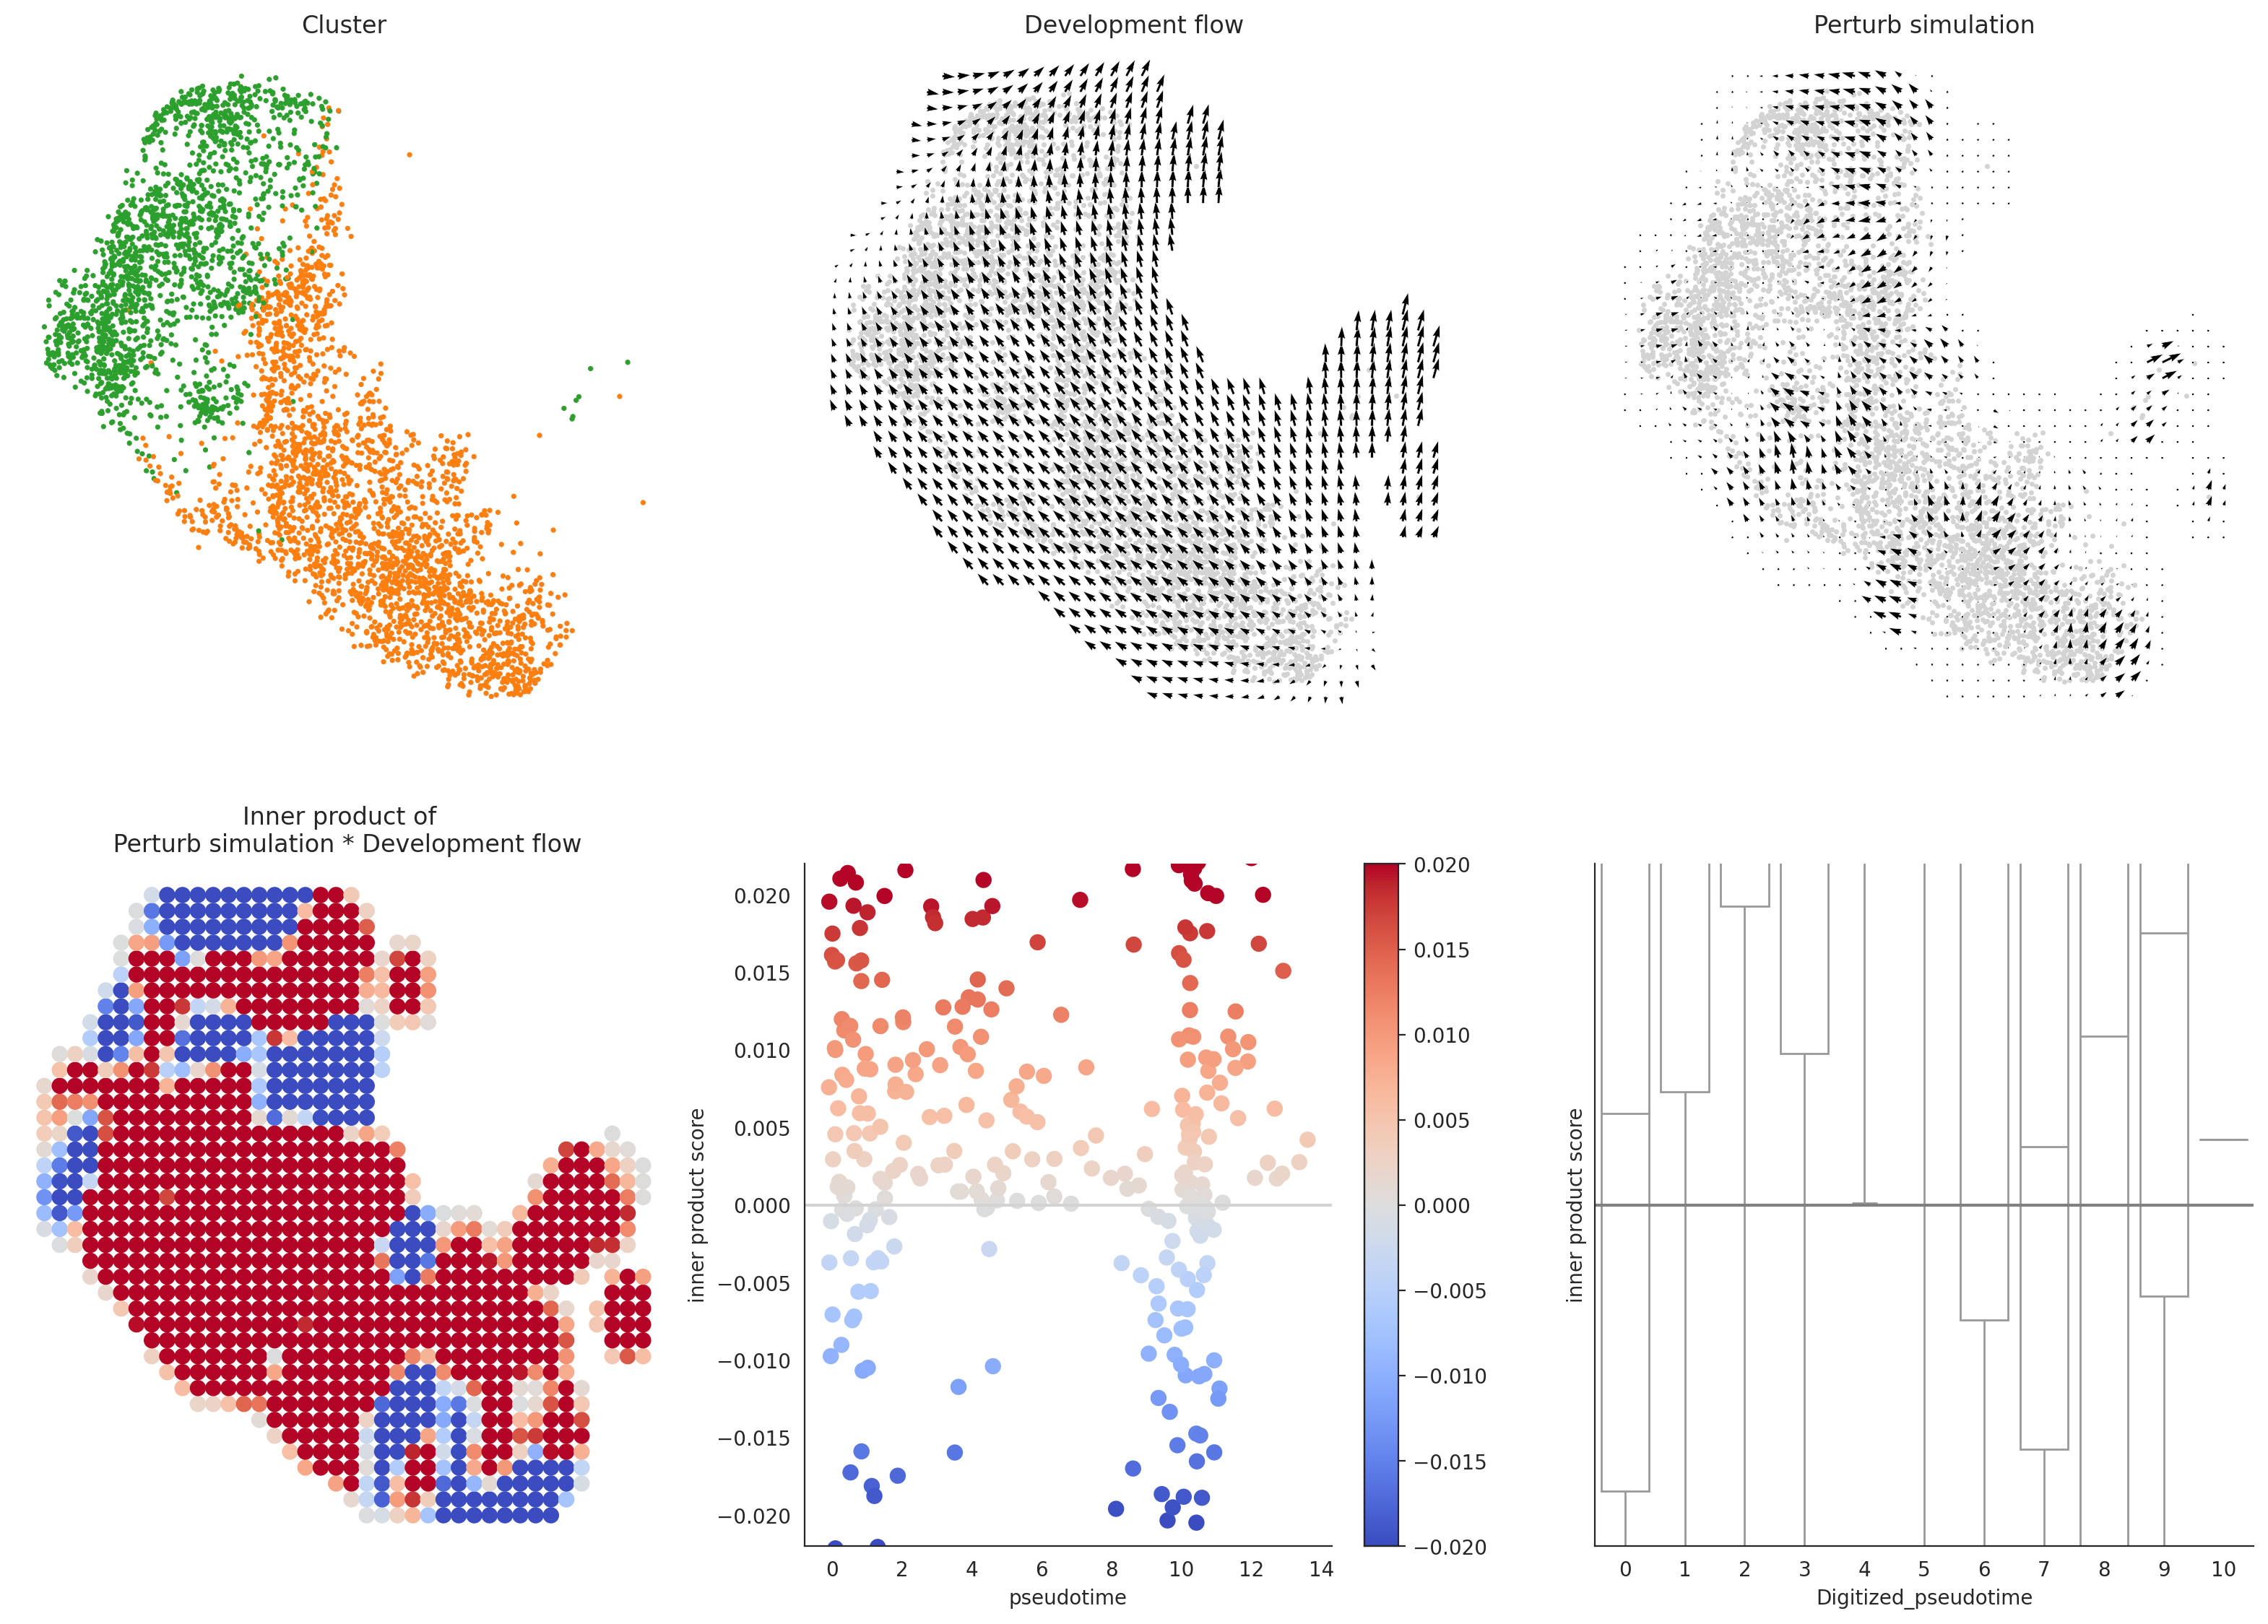

In [79]:
# Let's visualize the results
dev.visualize_development_module_layout_0(s=5,
                                          scale_for_simulation=scale_simulation,
                                          s_grid=50,
                                          scale_for_pseudotime=scale_dev,
                                          vm=vm)

# Save the figure
filename = "Celloracle_2.PNG"  # use save_folder.PNG directly as the filename
save_path = os.path.join(save_folder, filename)  # canonical path joining
plt.savefig(save_path, dpi=500, bbox_inches='tight')
print(f"Figure saved to: {save_path}")
